# bivariate and multivariate analysis

In [1]:
# Downlead the necessary libraries
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Load the data
clean_data = pd.read_excel("customers_sales_with_dxf_data.xlsx")
clean_data.head(5)

##Display all the data
#clean_data["customer_branch"].unique()
#pd.set_option("display.max_rows", None)
#
#display(clean_data)

FileNotFoundError: [Errno 2] No such file or directory: 'customers_sales_with_dxf_data.xlsx'

## Bivariate analysis

#### Boxplots


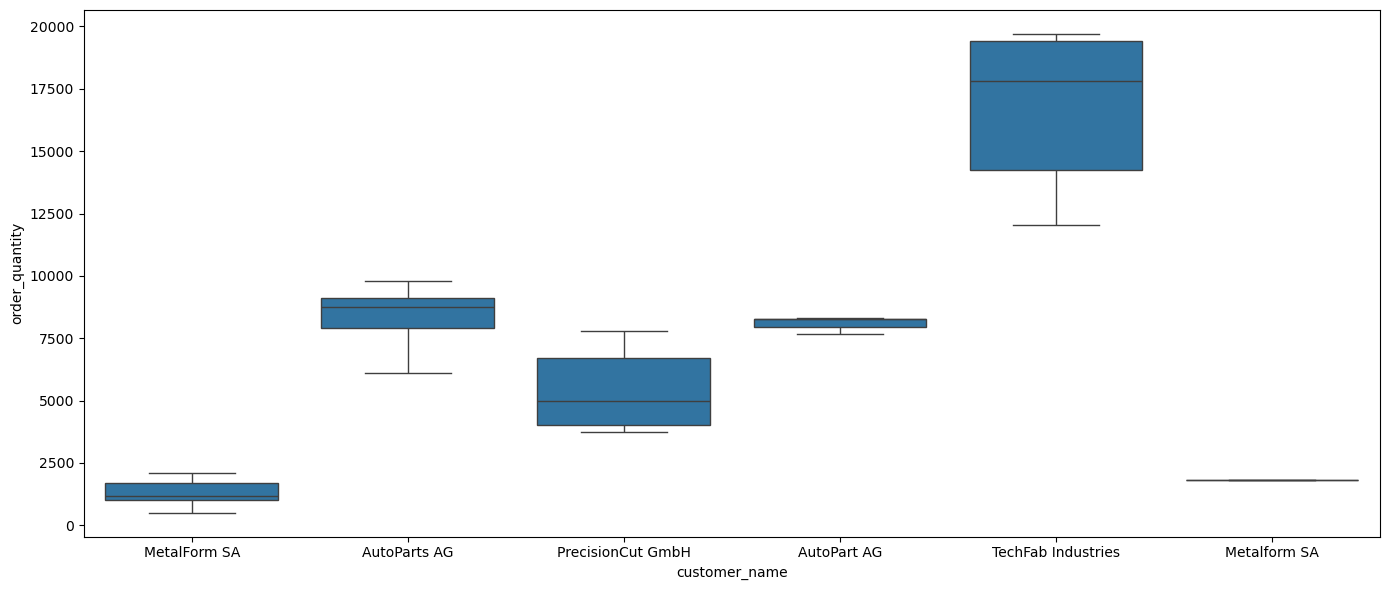

In [ ]:
# Boxplot for order quantities by customer
fig, axes = plt.subplots(1, 1, figsize=(14, 6))
sns.boxplot(clean_data, x='customer_name', y='order_quantity')
plt.tight_layout()
plt.show()

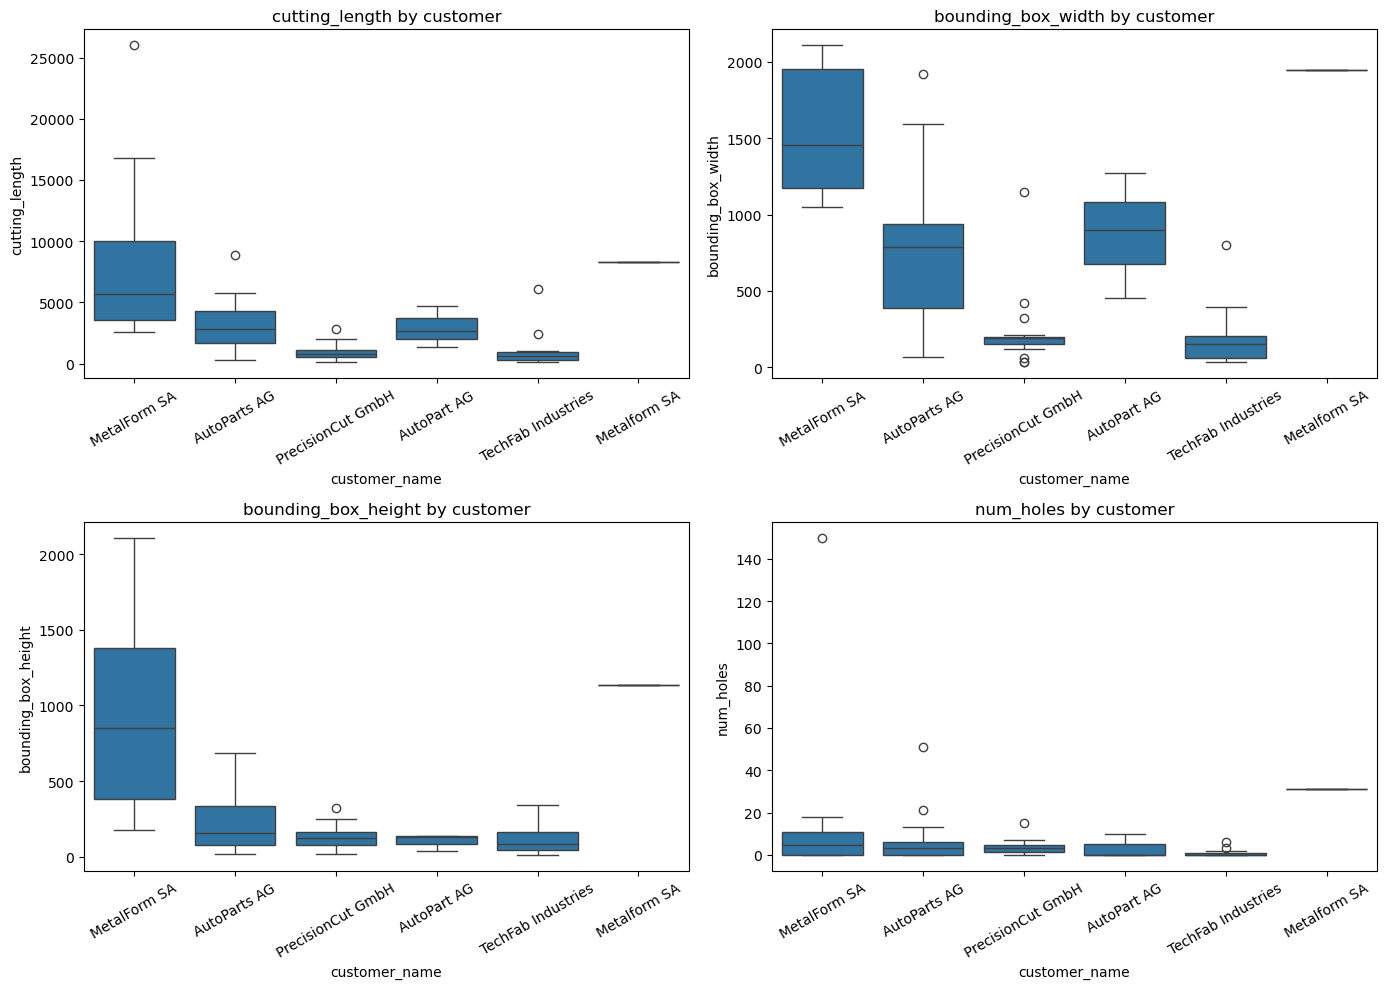

In [ ]:
# boxplots for cutting length, bounding box width, bounding box height, and number of holes by customer!
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
variables = [
    'cutting_length',
    'bounding_box_width',
    'bounding_box_height',
    'num_holes'
]

for ax, col in zip(axes.flat, variables):

    sns.boxplot(
        data=clean_data,
        x='customer_name',
        y=col,
        ax=ax
    )

    ax.set_title(f'{col} by customer')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

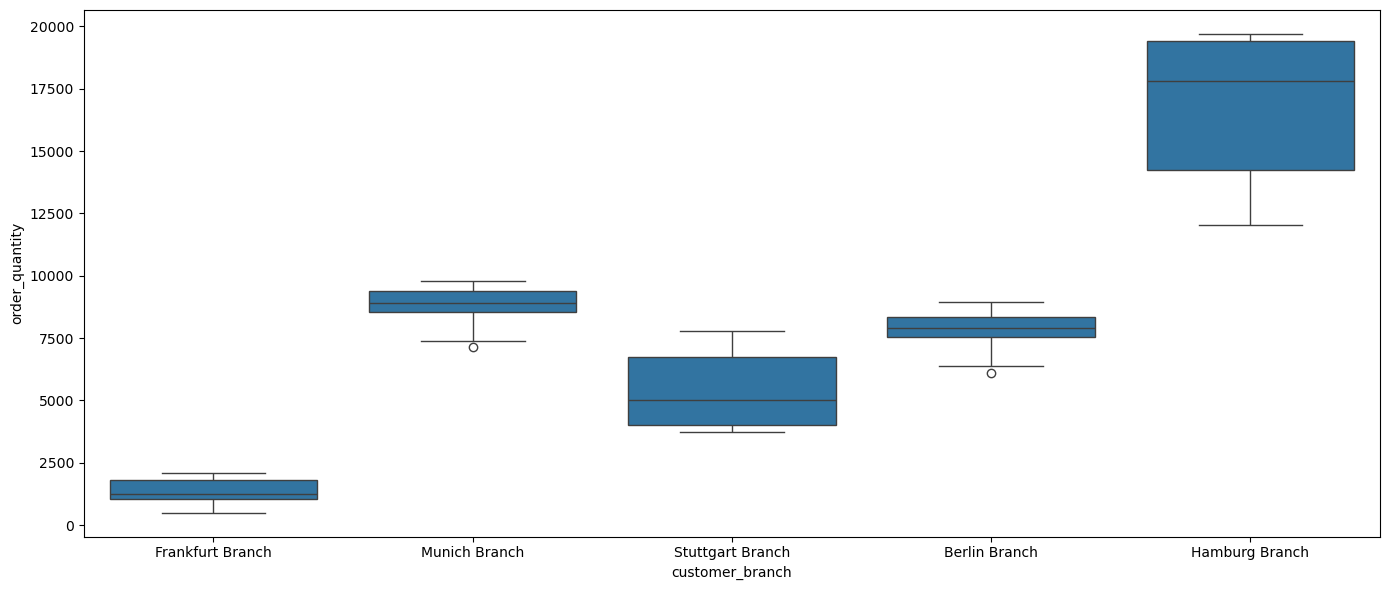

In [ ]:
# boxplot for customer branch by order quantity
fig, axes = plt.subplots(1, 1, figsize=(14, 6))
sns.boxplot(clean_data, x='customer_branch', y='order_quantity')
plt.tight_layout()
plt.show()

#### Scatterplots

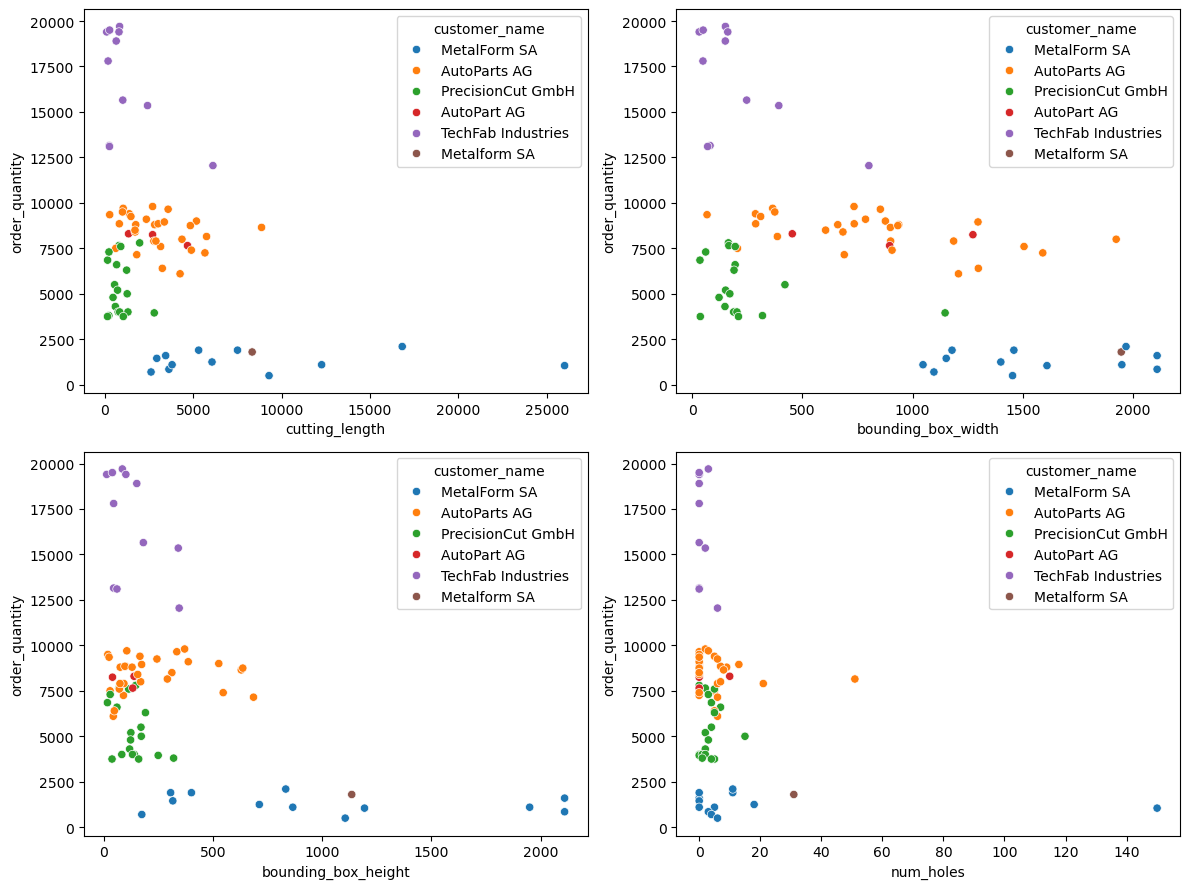

In [ ]:
#scatter plots to search for conections betweens the variables
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, ['cutting_length', 'bounding_box_width', 'bounding_box_height', 'num_holes']):
    sns.scatterplot(clean_data, x=col, y='order_quantity', hue='customer_name', ax=ax)
plt.tight_layout()
plt.show()

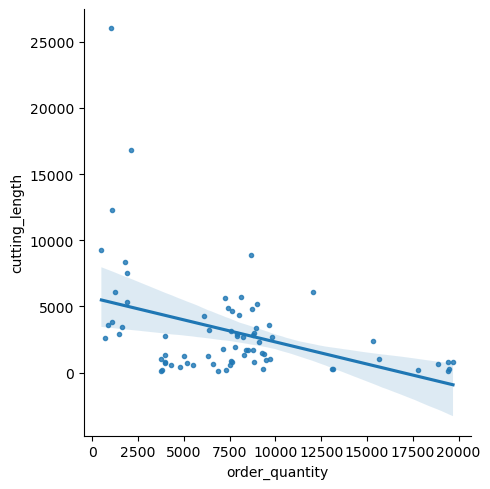

In [ ]:
# additional regression line
sns.lmplot(clean_data, x='order_quantity', y='cutting_length', markers='.')
plt.show()

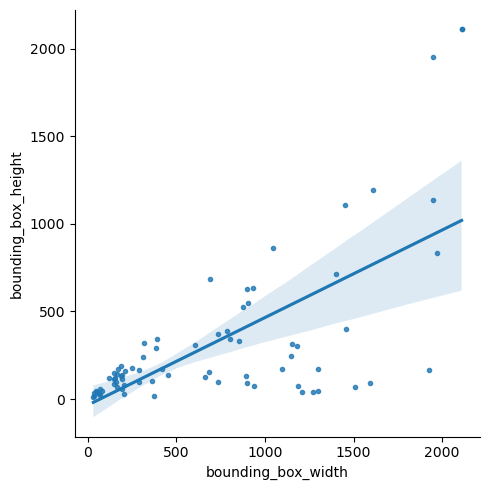

In [ ]:
sns.lmplot(clean_data, x='bounding_box_width', y='bounding_box_height', markers='.')
plt.show()

#### Histograms


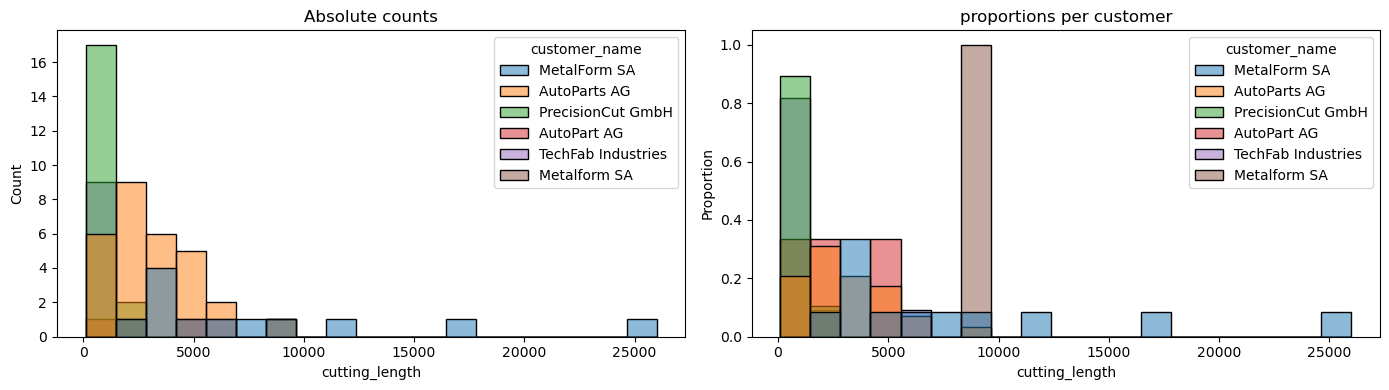

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(clean_data, x='cutting_length', hue='customer_name', ax=axes[0])
axes[0].set_title('Absolute counts')
sns.histplot(clean_data, x='cutting_length', hue='customer_name', stat='proportion', common_norm=False, ax=axes[1])
axes[1].set_title('proportions per customer')
plt.tight_layout()
plt.show()

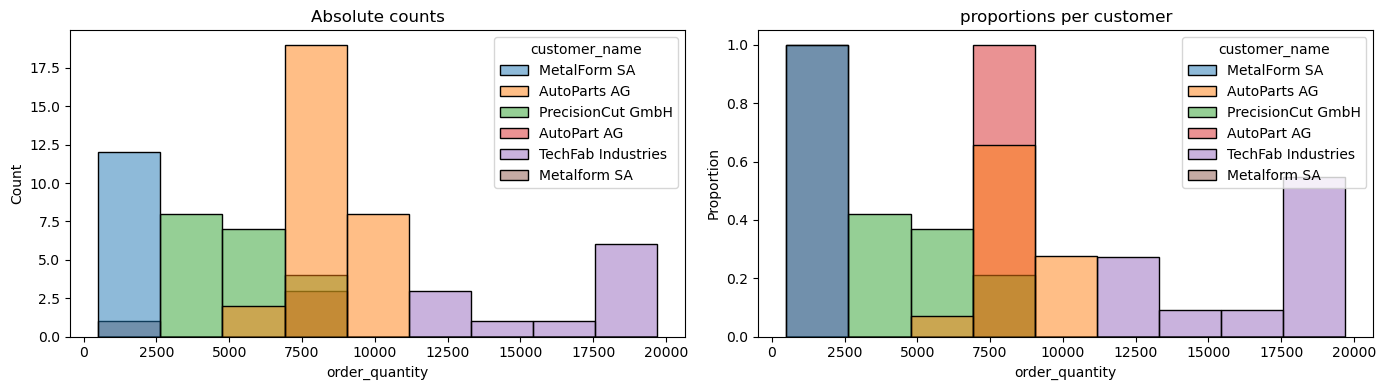

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(clean_data, x='order_quantity', hue='customer_name', ax=axes[0])
axes[0].set_title('Absolute counts')
sns.histplot(clean_data, x='order_quantity', hue='customer_name', stat='proportion', common_norm=False, ax=axes[1])
axes[1].set_title('proportions per customer')
plt.tight_layout()
plt.show()

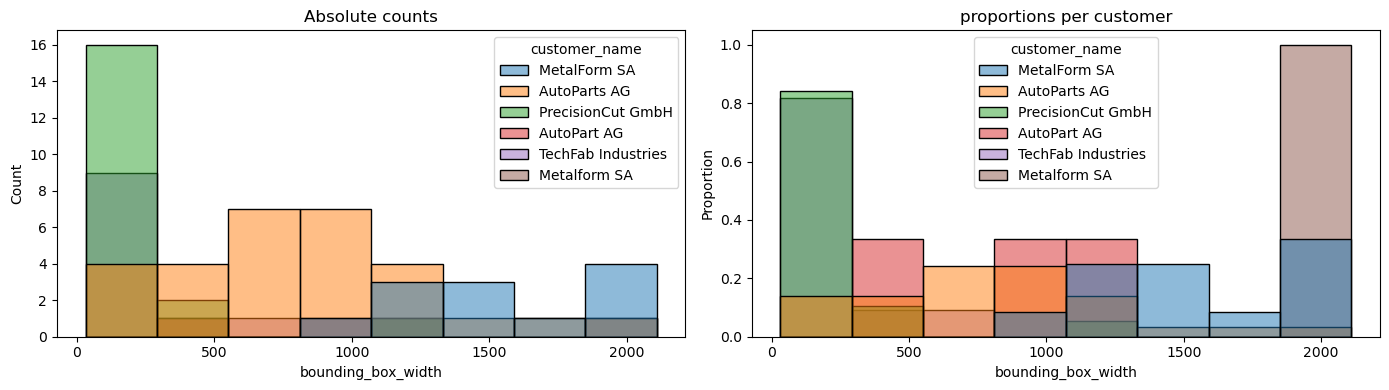

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(clean_data, x='bounding_box_width', hue='customer_name', ax=axes[0])
axes[0].set_title('Absolute counts')
sns.histplot(clean_data, x='bounding_box_width', hue='customer_name', stat='proportion', common_norm=False, ax=axes[1])
axes[1].set_title('proportions per customer')
plt.tight_layout()
plt.show()

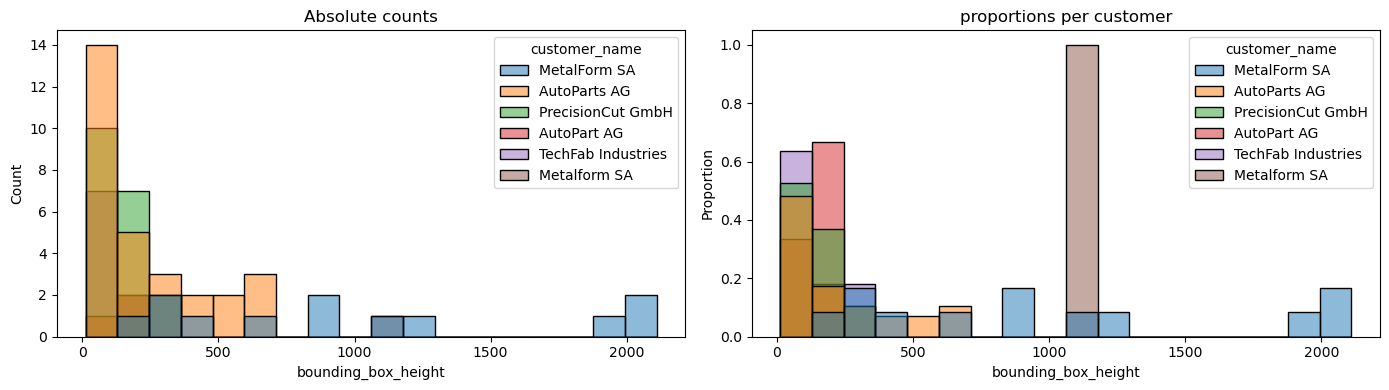

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(clean_data, x='bounding_box_height', hue='customer_name', ax=axes[0])
axes[0].set_title('Absolute counts')
sns.histplot(clean_data, x='bounding_box_height', hue='customer_name', stat='proportion', common_norm=False, ax=axes[1])
axes[1].set_title('proportions per customer')
plt.tight_layout()
plt.show()

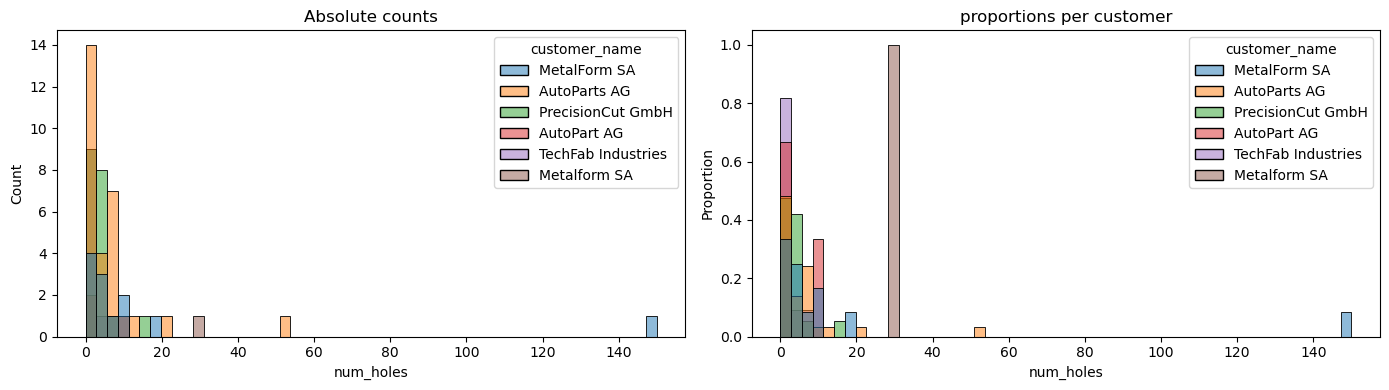

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(clean_data, x='num_holes', hue='customer_name', ax=axes[0])
axes[0].set_title('Absolute counts')
sns.histplot(clean_data, x='num_holes', hue='customer_name', stat='proportion', common_norm=False, ax=axes[1])
axes[1].set_title('proportions per customer')
plt.tight_layout()
plt.show()

## Multivariate analysis

#### Correlation matrix

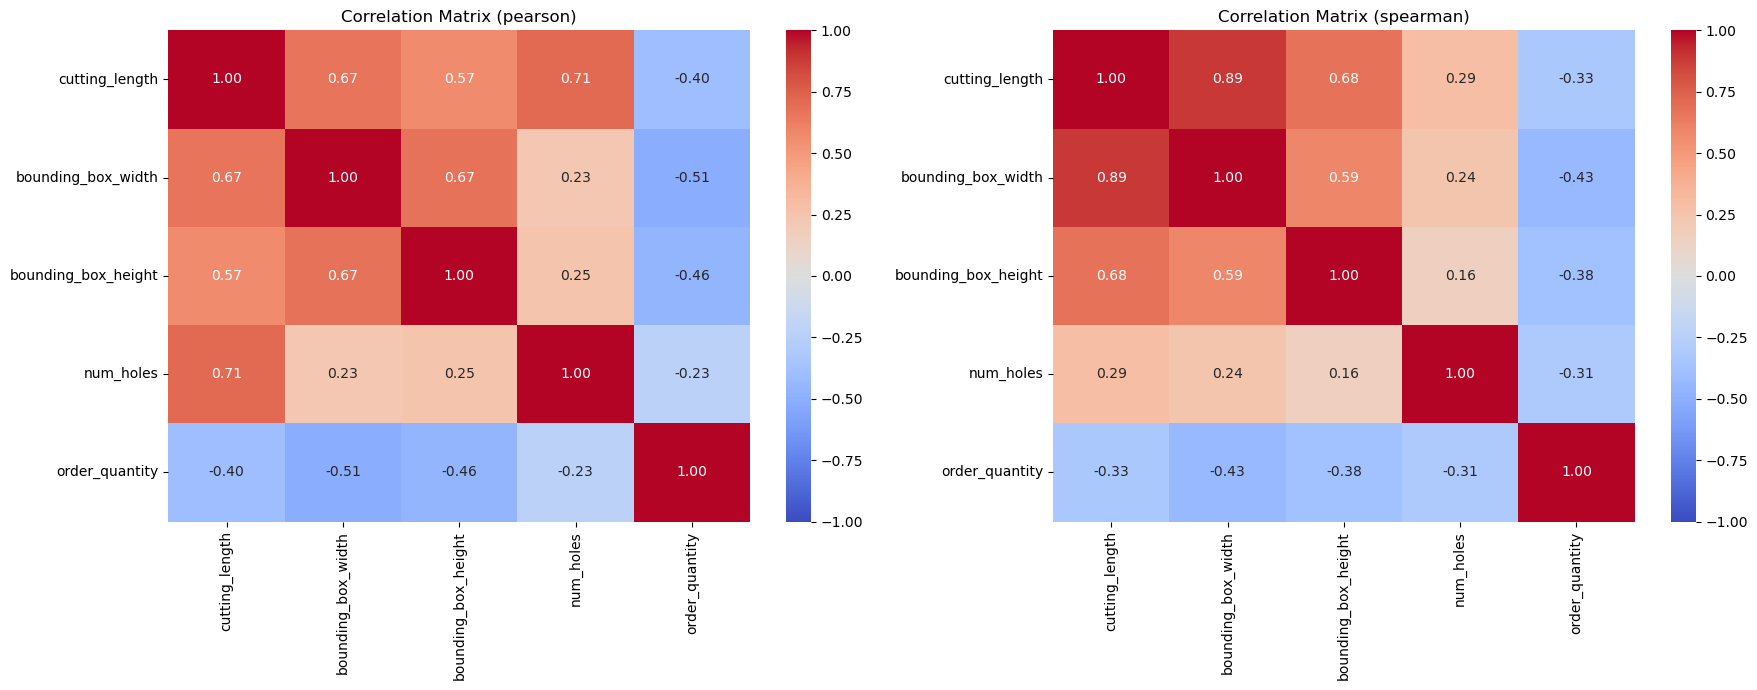

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, method in zip(axes, ['pearson', 'spearman']):
    sns.heatmap(clean_data[['cutting_length', 'bounding_box_width', 'bounding_box_height', 'num_holes', 'order_quantity']].corr(method=method), annot=True, fmt='.2f',
                cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
    ax.set_title(f'Correlation Matrix ({method})')
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import pearsonr, spearmanr

variables = [
    'order_quantity',
    'cutting_length',
    'bounding_box_width',
    'bounding_box_height',
    'num_holes'
]

results = []

for i in range(len(variables)):
    for j in range(i + 1, len(variables)):

        x = clean_data[variables[i]]
        y = clean_data[variables[j]]

        r_p, p_p = pearsonr(x, y)
        r_s, p_s = spearmanr(x, y)

        results.append({
            'Variable 1': variables[i],
            'Variable 2': variables[j],
            'Pearson r': r_p,
            'Pearson p': p_p,
            'Spearman rho': r_s,
            'Spearman p': p_s
        })

results_df = pd.DataFrame(results)
print(results_df.round(4))



            Variable 1           Variable 2  Pearson r  Pearson p  \
0       order_quantity       cutting_length    -0.4007     0.0004   
1       order_quantity   bounding_box_width    -0.5149     0.0000   
2       order_quantity  bounding_box_height    -0.4632     0.0000   
3       order_quantity            num_holes    -0.2274     0.0498   
4       cutting_length   bounding_box_width     0.6668     0.0000   
5       cutting_length  bounding_box_height     0.5662     0.0000   
6       cutting_length            num_holes     0.7129     0.0000   
7   bounding_box_width  bounding_box_height     0.6729     0.0000   
8   bounding_box_width            num_holes     0.2320     0.0452   
9  bounding_box_height            num_holes     0.2542     0.0277   

   Spearman rho  Spearman p  
0       -0.3277      0.0041  
1       -0.4319      0.0001  
2       -0.3808      0.0008  
3       -0.3057      0.0077  
4        0.8881      0.0000  
5        0.6759      0.0000  
6        0.2919      0.0111  


#### Pairplot

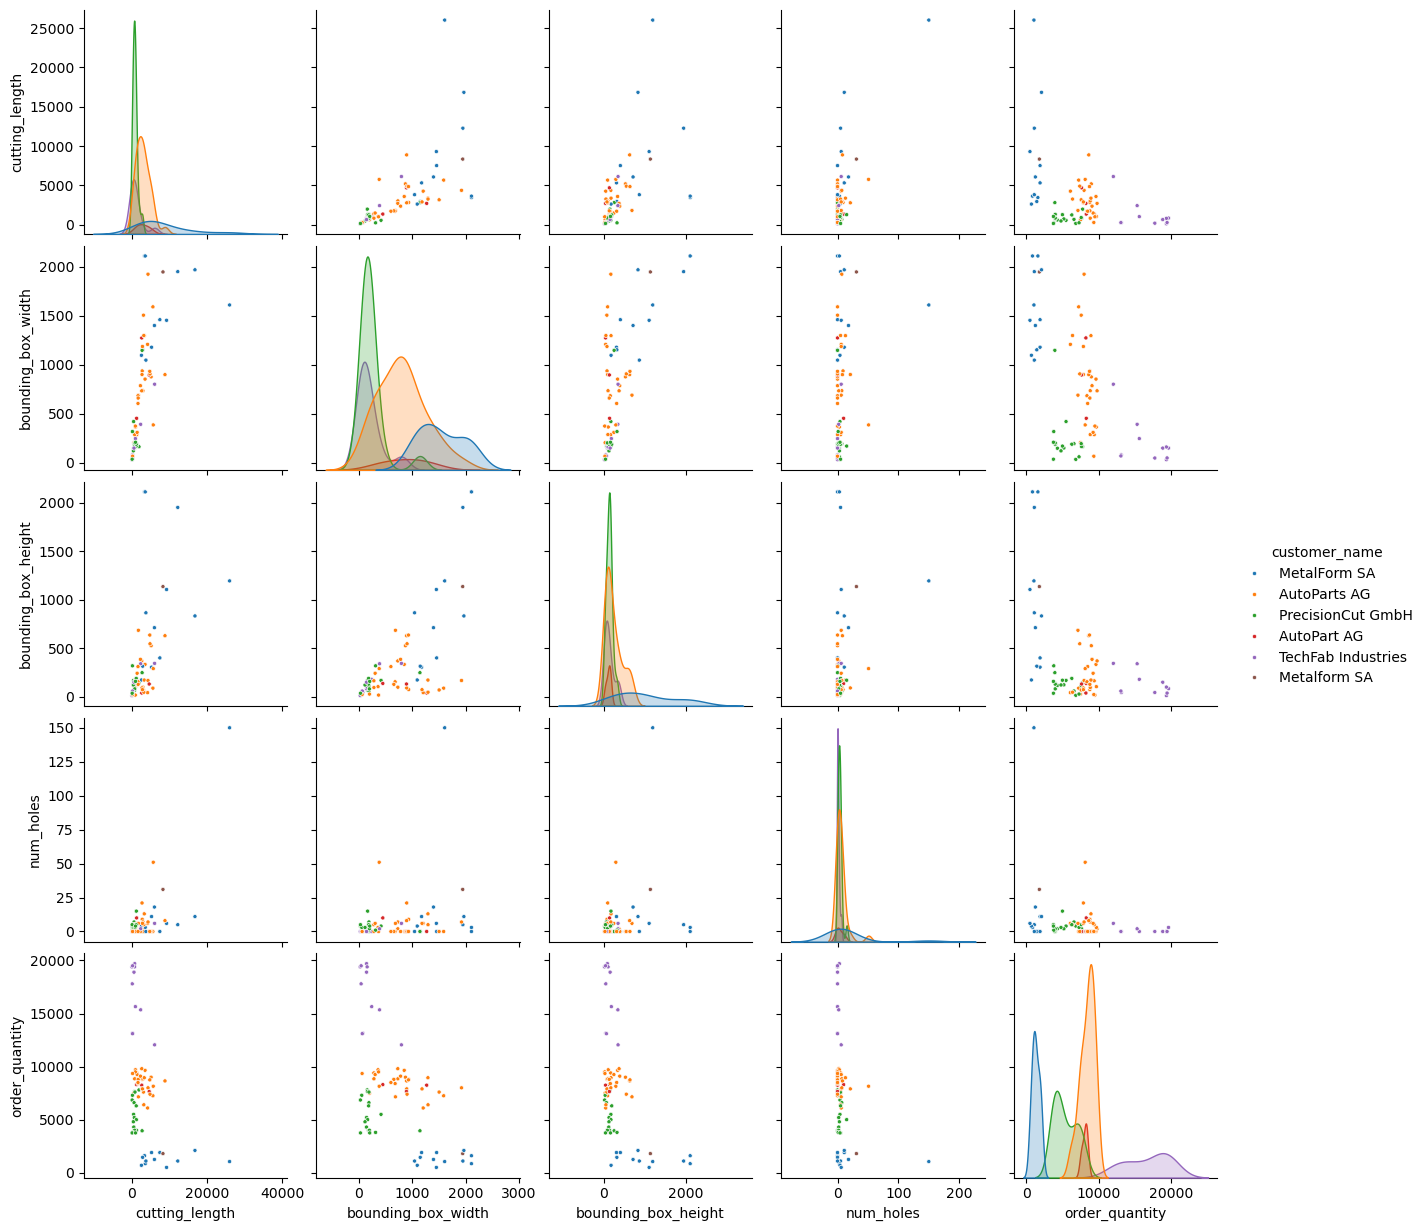

In [ ]:
sns.pairplot(clean_data, vars=['cutting_length', 'bounding_box_width', 'bounding_box_height', 'num_holes', 'order_quantity'], hue='customer_name', diag_kind='kde', markers='.')
plt.show()

# Outlier: Geo(54)